# Radius sensitivity (CCC)

## Spatial distance-weighted cell–cell interaction scoring

In [ ]:
import pandas as pd
import numpy as np
import cupy as cp
import tqdm
from scipy.spatial import cKDTree
import os
import pickle
import scanpy as sc
from Xenium_5K_IPF_constants import WORK_PATH

# Option
sc.settings.verbosity = 3

In [ ]:
# Constant Declaration
sigma = 150

In [ ]:
REV_PATH=f"{WORK_PATH}Revision/102/"
os.makedirs(REV_PATH, exist_ok=True)

In [ ]:
for r in [100, 200, 300, 400]:
    os.makedirs(f"{REV_PATH}interaction_scores_d{r}", exist_ok=True)

In [ ]:
adata = sc.read_h5ad(f"{WORK_PATH}AnnData/spatial_merged.h5ad")

In [ ]:
celltype_csv = pd.read_csv(f"{WORK_PATH}CSV/013_merge_type.csv", index_col="cell_id")
adata = adata[celltype_csv.index].copy()
adata.obs = pd.merge(adata.obs, celltype_csv[["cell_type", "subtype"]], left_index=True, right_index=True)

In [ ]:
# library size normalization
sc.pp.normalize_total(adata, target_sum=1e4)

In [ ]:
# Loading and filtering CellChat database
cellchat_db = pd.read_csv(f"{WORK_PATH}CellchatDB/CellChatDB.csv")
cellchat_db_ss = cellchat_db[cellchat_db["annotation"] == "Secreted Signaling"].copy()

cellchat_db_ss = pd.DataFrame({
    "pathway_name": cellchat_db_ss["pathway_name"].values,
    "ligand": cellchat_db_ss["ligand"].values,
    "receptor": cellchat_db_ss["receptor"].values,
    "lig_list": cellchat_db_ss["ligand.symbol"].str.split(",").apply(lambda L: [s.strip() for s in L]).values,
    "rec_list": cellchat_db_ss["receptor.symbol"].str.split(",").apply(lambda L: [s.strip() for s in L]).values,
})

cellchat_db_ss["gene_list"] = cellchat_db_ss.apply(
    lambda r: sorted(set(r["lig_list"] + r["rec_list"])), 
    axis=1
)

cellchat_db_ss["interaction_name"] = cellchat_db_ss["ligand"] + " - " + cellchat_db_ss["receptor"]

In [ ]:
# Sort genes
cellchat_all_genes=set(cellchat_db_ss["gene_list"].sum())
sorted_genes = sorted(set(adata.var_names) & set(cellchat_all_genes))

expr = adata[:, sorted_genes].to_df()
gene_to_col = {g: i for i, g in enumerate(expr.columns)} 

In [ ]:
cellchat_db_f=pd.read_pickle(f"{WORK_PATH}Interaction/interaction_data.pkl")

In [ ]:
# Geometric mean function definition
def geometric_mean(expr_g: cp.ndarray, col_ids: list[int]) -> cp.ndarray:
    if not col_ids:
        return cp.zeros(expr_g.shape[0], dtype=cp.float32)
    vals = expr_g[:, col_ids]
    return cp.exp(cp.mean(cp.log(vals), axis=1)).astype(cp.float32)

In [ ]:
# create edges of the interest cells
coords = adata.obsm["spatial"]
tree = cKDTree(coords)

is_interest = (adata.obs["cell_type"].values == "Epithelial") 
interest_idx = np.where(is_interest)[0]

In [ ]:
for r in [100, 200, 300, 400]:
    # Get cell coordinates within R mm of each interest cell (Neighbor cells).
    neighbor_from_interest = tree.query_ball_point(coords[interest_idx], r=r)
    
    # Edge sets
    int_to_nei_edges = []  # list of tuples (e, np.array(nei_interests))
    for n, neis in enumerate(neighbor_from_interest):
        if not neis:
            continue
        e = interest_idx[n]
        neis = [m for m in neis if m != e]  # int ≠ nei
        if neis:
            int_to_nei_edges.append((e, np.array(neis, dtype=int)))
    
    # Convert to cupy for GPU
    expr_cp   = cp.asarray(expr.values, dtype=cp.float32)
    coords_cp = cp.asarray(coords, dtype=cp.float32)
    
    # Calculate weights in advance (Gaussian filter)
    edge_list = []
    w_list    = []
    coeff = -1.0 / (2.0 * sigma * sigma)  # coefficient
    
    for e, nei_arr in int_to_nei_edges: 
        nei_cp = cp.asarray(nei_arr, dtype=cp.int32)
        d2     = cp.sum((coords_cp[nei_cp] - coords_cp[e])**2, axis=1)
        w      = cp.exp(coeff * d2).astype(cp.float32)
        edge_list.append((e, nei_cp))  # interest cell index and neighbor indices
        w_list.append(w)               # weights for the intererst–neighbor pairs
        
    for _, row in tqdm.tqdm(cellchat_db_f.iterrows(), total=len(cellchat_db_f)):
    
        lig_idx = [gene_to_col[g] for g in row["lig_list"] if g in gene_to_col]
        rec_idx = [gene_to_col[g] for g in row["rec_list"] if g in gene_to_col]
        
        if not lig_idx or not rec_idx:
            continue
    
        geo_lig_all = geometric_mean(expr_cp, lig_idx)  
        geo_rec_all = geometric_mean(expr_cp, rec_idx) 
    
        scores_nei_to_int = {}
        scores_int_to_nei = {}
    
        for (it, ni), w in zip(edge_list, w_list):
            s_nei2int = geo_lig_all[ni] * geo_rec_all[it] * w
            m1 = s_nei2int > 0
            if m1.any().item():  
                idx = cp.asnumpy(ni[m1])
                val = cp.asnumpy(s_nei2int[m1])
                scores_nei_to_int.update({(int(j), int(it)): float(s) for j, s in zip(idx, val)})
    
            s_int2nei = geo_lig_all[it] * geo_rec_all[ni] * w
            m2 = s_int2nei > 0
            if m2.any().item(): 
                idx = cp.asnumpy(ni[m2])
                val = cp.asnumpy(s_int2nei[m2])
                scores_int_to_nei.update({(int(it), int(j)): float(s) for j, s in zip(idx, val)})
    
        if scores_nei_to_int or scores_int_to_nei:
            with open(os.path.join(f"{REV_PATH}interaction_scores_d{r}", f"{row["interaction_name"]}.pkl"), "wb") as f:
                pickle.dump({"nei_to_int": scores_nei_to_int, "int_to_nei": scores_int_to_nei}, f)

## Aggregation of cell–cell interaction by subtype

In [ ]:
import pandas as pd
import numpy as np
import tqdm
import os
import pickle
import glob
import shutil
from Xenium_5K_IPF_constants import ALL_SUBTYPE_LIST, WORK_PATH

# Constant Declaration
B   = 10000  # number of iterations for a permutation test
rng = np.random.default_rng(42)  # random seed

REV_PATH=f"{WORK_PATH}Revision/102/"

In [ ]:
# Loading meta data
meta = pd.read_csv(f"{WORK_PATH}CSV/013_merge_type.csv", index_col="cell_id")

# Data unification
cell_type_arr = meta["cell_type"].astype(str).values
subtype_arr   = meta["subtype"].astype(str).values

# subtypes of the interest cell group
interest_subtype= meta.loc[meta["cell_type"]=="Epithelial", "subtype"].unique()
int_subtype_list = [a for a in ALL_SUBTYPE_LIST if a in interest_subtype]

In [ ]:
# interest cell IDs
is_interest = (cell_type_arr == "Epithelial")
interest_idx = np.where(is_interest)[0] 

# Linking subtypes to IDs
all_subtypes  = np.unique(subtype_arr)
subtype_to_id = {s:i for i,s in enumerate(all_subtypes)}
id_to_subtype = {i:s for s,i in subtype_to_id.items()}
subtype_ids   = np.array([subtype_to_id[s] for s in subtype_arr], dtype=np.int32)

# counts of interest cells
counts_target  = pd.Series(subtype_arr[interest_idx]).value_counts().to_dict() 

In [ ]:
def aggregate_and_permute(edge_dict: dict, direction: str, pathway_name: str) -> list:
    if not edge_dict:
        return []

    if direction == "nei_to_int":
        row_names = ALL_SUBTYPE_LIST
        col_names = int_subtype_list
    elif direction == "int_to_nei":
        row_names = int_subtype_list
        col_names = ALL_SUBTYPE_LIST

    R, C = len(row_names), len(col_names)

    row_global_ids = np.array([subtype_to_id[n] for n in row_names], dtype=np.int32)
    col_global_ids = np.array([subtype_to_id[n] for n in col_names], dtype=np.int32)

    # global id -> local index
    nS = len(id_to_subtype)
    row_map = -np.ones(nS, dtype=np.int32); row_map[row_global_ids] = np.arange(R, dtype=np.int32)
    col_map = -np.ones(nS, dtype=np.int32); col_map[col_global_ids] = np.arange(C, dtype=np.int32)

    # Edge arraying
    items  = list(edge_dict.items())  # ((sender_idx, reciever_idx), scores)
    pairs  = np.array([k for k, _ in items], dtype=object)  # (sender_idx, reciever_idx)
    scores = np.array([v for _, v in items], dtype=np.float64) # scores
    src_idx = pairs[:,0].astype(int)  # sender_idx
    tgt_idx = pairs[:,1].astype(int)  # reciever_idx

    # global subtype id
    if direction == "nei_to_int":
        row_src_global = subtype_ids[src_idx]   # row = neighbor
        col_tgt_global = subtype_ids[tgt_idx]   # column = interest
        # denominator: interest (tgt)
        denom = np.array([counts_target.get(id_to_subtype[sid], 0) for sid in col_tgt_global], dtype=np.int64)
        # Shuffle Target = neighbor（src）
        nei_idx_for_shuffle = src_idx
    else:  # 'int_to_nei'
        row_src_global = subtype_ids[src_idx]   # row = interest
        col_tgt_global = subtype_ids[tgt_idx]   # column = neighbor
        # denominator: interest (src)
        denom = np.array([counts_target.get(id_to_subtype[sid], 0) for sid in row_src_global], dtype=np.int64)
        # Shuffle Target = neighbor（tgt）
        nei_idx_for_shuffle = tgt_idx

    # Global → fixed grid local indices
    row_idx = row_map[row_src_global]
    col_idx = col_map[col_tgt_global]

    # Validate egdes
    valid = (row_idx >= 0) & (col_idx >= 0) & (denom > 0)
    if not np.any(valid):
        return None
    row_idx = row_idx[valid]
    col_idx = col_idx[valid]
    scores  = scores[valid]
    denom   = denom[valid]
    nei_idx_for_shuffle = nei_idx_for_shuffle[valid]
    
   # Observation matrix（fixed size R x C）----
    obs_mat = np.zeros((R, C), dtype=np.float64)
    np.add.at(obs_mat, (row_idx, col_idx), scores / denom)

    # neighbor-only permutation
    # unique neighbor cells, inverse index
    unique_nei, nei_pos_per_edge = np.unique(nei_idx_for_shuffle, return_inverse=True) # nei_pos_per_edge: 各エッジの neighbor が unique_nei のどの位置か
    nei_cell_sub_global = subtype_ids[unique_nei]  # global subtype IDs of neighbors

    ge_counts = np.zeros((R, C), dtype=np.int32)

    # Permutation test
    for _ in range(B):
        shuf = rng.permutation(nei_cell_sub_global)      # Permute global subtype IDs of neighbors
        nei_perm_global = shuf[nei_pos_per_edge]         # The replaced global subtype ID of each edge

        perm_mat = np.zeros((R, C), dtype=np.float64)
        if direction == "nei_to_int":
            row_perm = row_map[nei_perm_global]          # permute rows（neighbor）
            np.add.at(perm_mat, (row_perm, col_idx), scores / denom)
        else:  # 'tar_to_nei'
            col_perm = col_map[nei_perm_global]          # permute columns（neighbor）
            np.add.at(perm_mat, (row_idx, col_perm), scores / denom)

        ge_counts += (perm_mat >= obs_mat)

    # +1 correction
    pvals = (ge_counts + 1) / (B + 1)

    # Output
    rows_out = []
    for i in range(R):
        for j in range(C):
            if obs_mat[i, j] == 0 and ge_counts[i, j] == 0:
                continue
            rows_out.append({
                "Pathway": pathway_name,
                "Direction": direction,
                "Source_Subtype": row_names[i],
                "Target_Subtype": col_names[j],
                "Observed": float(obs_mat[i, j]),
                "GE_Count": int(ge_counts[i, j]),
                "B": B,
                "P_value": float(pvals[i, j]),
            })
    return rows_out


In [ ]:
# Execution part
for r in [100, 200, 300, 400]:
    all_rows = []
    for fpath in tqdm.tqdm(sorted(glob.glob(os.path.join(f"{REV_PATH}interaction_scores_d{r}", "*.pkl")))):
        pathway_name = os.path.splitext(os.path.basename(fpath))[0]
        with open(fpath, "rb") as f:
            obj = pickle.load(f)
    
        nei2int = obj.get("nei_to_int", {})
        int2nei = obj.get("int_to_nei", {})
    
        rows = aggregate_and_permute(nei2int, "nei_to_int", pathway_name)
        if rows: all_rows.extend(rows)
    
        rows = aggregate_and_permute(int2nei, "int_to_nei", pathway_name)
        if rows: all_rows.extend(rows)
    # Saving
    pd.DataFrame(all_rows).to_csv(f"{REV_PATH}perm_results_d{r}.csv", index=False, encoding="utf-8-sig")

## Statistics

In [ ]:
import plotly.graph_objects as go
import plotly.io as pio
import colorcet as cc
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from statsmodels.stats.multitest import multipletests
import pickle
from Xenium_5K_IPF_constants import ALL_SUBTYPE_LIST, WORK_PATH

# Option
plt.rcParams["font.family"] = "Fira Sans" 
%matplotlib ipympl

# Constant Declaration
direc = ["nei_to_int", "int_to_nei"]  # interactopm directions

REV_PATH=f"{WORK_PATH}Revision/102/"

In [ ]:
rad = 100

In [ ]:
perm_df = pd.read_csv(f"{REV_PATH}perm_results_d{rad}.csv")
perm_df.set_index("Pathway", inplace=True)

cellchat_db_f=pd.read_pickle(f"{WORK_PATH}Interaction/interaction_data.pkl")
cellchat_db_f.set_index("interaction_name", inplace=True)

perm_df_merge = pd.merge(perm_df, cellchat_db_f[["pathway_name"]], left_index=True, right_index=True)

In [ ]:
perm_df_direc = [
    perm_df_merge[perm_df_merge["Direction"]==direc[0]],
    perm_df_merge[perm_df_merge["Direction"]==direc[1]]
]

In [ ]:
perm_df_sig = []
for pm in perm_df_direc:
    reject, pvals_corrected, _, _ = multipletests(pm["P_value"], alpha=0.05, method="fdr_bh")
    pm.loc[:, "FDR_qval"]= pvals_corrected
    pm.loc[:, "Significant"] = reject
    pm = pm[pm["Significant"]].sort_values("Observed", ascending=False)
    pm.loc[:, "Obs_log"] = np.log10(pm["Observed"])  # log transformation
    pm.loc[:, "Obs_norm"] = (pm["Obs_log"]-pm["Obs_log"].min())/(pm["Obs_log"].max()-pm["Obs_log"].min())  # min–max normalization
    pm.to_csv(f"{REV_PATH}significant_pathway_in_d{rad}_{pm["Direction"].iloc[0]}.csv", encoding="utf-8-sig")
    perm_df_sig.append(pm)

# Sigma sensitivity (CCC)

## Spatial distance-weighted cell–cell interaction scoring

In [ ]:
import pandas as pd
import numpy as np
import cupy as cp
import tqdm
from scipy.spatial import cKDTree
import os
import pickle
import scanpy as sc
from Xenium_5K_IPF_constants import WORK_PATH

# Option
sc.settings.verbosity = 3

In [ ]:
# Constant Declaration
rad = 300

In [ ]:
REV_PATH=f"{WORK_PATH}Revision/102/"
os.makedirs(REV_PATH, exist_ok=True)

In [ ]:
for sig in [50, 100, 200]:
    os.makedirs(f"{REV_PATH}interaction_scores_s{sig}", exist_ok=True)

In [ ]:
adata = sc.read_h5ad(f"{WORK_PATH}AnnData/spatial_merged.h5ad")

In [ ]:
celltype_csv = pd.read_csv(f"{WORK_PATH}CSV/013_merge_type.csv", index_col="cell_id")
adata = adata[celltype_csv.index].copy()
adata.obs = pd.merge(adata.obs, celltype_csv[["cell_type", "subtype"]], left_index=True, right_index=True)

In [ ]:
# library size normalization
sc.pp.normalize_total(adata, target_sum=1e4)

In [ ]:
# Loading and filtering CellChat database
cellchat_db = pd.read_csv(f"{WORK_PATH}CellchatDB/CellChatDB.csv")
cellchat_db_ss = cellchat_db[cellchat_db["annotation"] == "Secreted Signaling"].copy()

cellchat_db_ss = pd.DataFrame({
    "pathway_name": cellchat_db_ss["pathway_name"].values,
    "ligand": cellchat_db_ss["ligand"].values,
    "receptor": cellchat_db_ss["receptor"].values,
    "lig_list": cellchat_db_ss["ligand.symbol"].str.split(",").apply(lambda L: [s.strip() for s in L]).values,
    "rec_list": cellchat_db_ss["receptor.symbol"].str.split(",").apply(lambda L: [s.strip() for s in L]).values,
})

cellchat_db_ss["gene_list"] = cellchat_db_ss.apply(
    lambda r: sorted(set(r["lig_list"] + r["rec_list"])), 
    axis=1
)

cellchat_db_ss["interaction_name"] = cellchat_db_ss["ligand"] + " - " + cellchat_db_ss["receptor"]

In [ ]:
# Sort genes
cellchat_all_genes=set(cellchat_db_ss["gene_list"].sum())
sorted_genes = sorted(set(adata.var_names) & set(cellchat_all_genes))

expr = adata[:, sorted_genes].to_df()
gene_to_col = {g: i for i, g in enumerate(expr.columns)} 

In [ ]:
cellchat_db_f=pd.read_pickle(f"{WORK_PATH}Interaction/interaction_data.pkl")

In [ ]:
# Geometric mean function definition
def geometric_mean(expr_g: cp.ndarray, col_ids: list[int]) -> cp.ndarray:
    if not col_ids:
        return cp.zeros(expr_g.shape[0], dtype=cp.float32)
    vals = expr_g[:, col_ids]
    return cp.exp(cp.mean(cp.log(vals), axis=1)).astype(cp.float32)

In [ ]:
# create edges of the interest cells
coords = adata.obsm["spatial"]
tree = cKDTree(coords)

is_interest = (adata.obs["cell_type"].values == "Epithelial") 
interest_idx = np.where(is_interest)[0]

In [ ]:
for sig in [50, 200]:
    # Get cell coordinates within R mm of each interest cell (Neighbor cells).
    neighbor_from_interest = tree.query_ball_point(coords[interest_idx], r=rad)
    
    # Edge sets
    int_to_nei_edges = []  # list of tuples (e, np.array(nei_interests))
    for n, neis in enumerate(neighbor_from_interest):
        if not neis:
            continue
        e = interest_idx[n]
        neis = [m for m in neis if m != e]  # int ≠ nei
        if neis:
            int_to_nei_edges.append((e, np.array(neis, dtype=int)))
    
    # Convert to cupy for GPU
    expr_cp   = cp.asarray(expr.values, dtype=cp.float32)
    coords_cp = cp.asarray(coords, dtype=cp.float32)
    
    # Calculate weights in advance (Gaussian filter)
    edge_list = []
    w_list    = []
    coeff = -1.0 / (2.0 * sig * sig)  # coefficient
    
    for e, nei_arr in int_to_nei_edges: 
        nei_cp = cp.asarray(nei_arr, dtype=cp.int32)
        d2     = cp.sum((coords_cp[nei_cp] - coords_cp[e])**2, axis=1)
        w      = cp.exp(coeff * d2).astype(cp.float32)
        edge_list.append((e, nei_cp))  # interest cell index and neighbor indices
        w_list.append(w)               # weights for the intererst–neighbor pairs
        
    for _, row in tqdm.tqdm(cellchat_db_f.iterrows(), total=len(cellchat_db_f)):
    
        lig_idx = [gene_to_col[g] for g in row["lig_list"] if g in gene_to_col]
        rec_idx = [gene_to_col[g] for g in row["rec_list"] if g in gene_to_col]
        
        if not lig_idx or not rec_idx:
            continue
    
        geo_lig_all = geometric_mean(expr_cp, lig_idx)  
        geo_rec_all = geometric_mean(expr_cp, rec_idx) 
    
        scores_nei_to_int = {}
        scores_int_to_nei = {}
    
        for (it, ni), w in zip(edge_list, w_list):
            s_nei2int = geo_lig_all[ni] * geo_rec_all[it] * w
            m1 = s_nei2int > 0
            if m1.any().item():  
                idx = cp.asnumpy(ni[m1])
                val = cp.asnumpy(s_nei2int[m1])
                scores_nei_to_int.update({(int(j), int(it)): float(s) for j, s in zip(idx, val)})
    
            s_int2nei = geo_lig_all[it] * geo_rec_all[ni] * w
            m2 = s_int2nei > 0
            if m2.any().item(): 
                idx = cp.asnumpy(ni[m2])
                val = cp.asnumpy(s_int2nei[m2])
                scores_int_to_nei.update({(int(it), int(j)): float(s) for j, s in zip(idx, val)})
    
        if scores_nei_to_int or scores_int_to_nei:
            with open(os.path.join(f"{REV_PATH}interaction_scores_s{sig}", f"{row["interaction_name"]}.pkl"), "wb") as f:
                pickle.dump({"nei_to_int": scores_nei_to_int, "int_to_nei": scores_int_to_nei}, f)

## Aggregation of cell–cell interaction by subtype

In [ ]:
import pandas as pd
import numpy as np
import tqdm
import os
import pickle
import glob
from Xenium_5K_IPF_constants import ALL_SUBTYPE_LIST, WORK_PATH

# Constant Declaration
B   = 10000  # number of iterations for a permutation test
rng = np.random.default_rng(42)  # random seed

REV_PATH=f"{WORK_PATH}Revision/102/"

In [ ]:
# Loading meta data
meta = pd.read_csv(f"{WORK_PATH}CSV/013_merge_type.csv", index_col="cell_id")

# Data unification
cell_type_arr = meta["cell_type"].astype(str).values
subtype_arr   = meta["subtype"].astype(str).values

# subtypes of the interest cell group
interest_subtype= meta.loc[meta["cell_type"]=="Epithelial", "subtype"].unique()
int_subtype_list = [a for a in ALL_SUBTYPE_LIST if a in interest_subtype]

In [ ]:
# interest cell IDs
is_interest = (cell_type_arr == "Epithelial")
interest_idx = np.where(is_interest)[0] 

# Linking subtypes to IDs
all_subtypes  = np.unique(subtype_arr)
subtype_to_id = {s:i for i,s in enumerate(all_subtypes)}
id_to_subtype = {i:s for s,i in subtype_to_id.items()}
subtype_ids   = np.array([subtype_to_id[s] for s in subtype_arr], dtype=np.int32)

# counts of interest cells
counts_target  = pd.Series(subtype_arr[interest_idx]).value_counts().to_dict() 

In [ ]:
def aggregate_and_permute(edge_dict: dict, direction: str, pathway_name: str) -> list:
    if not edge_dict:
        return []

    if direction == "nei_to_int":
        row_names = ALL_SUBTYPE_LIST
        col_names = int_subtype_list
    elif direction == "int_to_nei":
        row_names = int_subtype_list
        col_names = ALL_SUBTYPE_LIST

    R, C = len(row_names), len(col_names)

    row_global_ids = np.array([subtype_to_id[n] for n in row_names], dtype=np.int32)
    col_global_ids = np.array([subtype_to_id[n] for n in col_names], dtype=np.int32)

    # global id -> local index
    nS = len(id_to_subtype)
    row_map = -np.ones(nS, dtype=np.int32); row_map[row_global_ids] = np.arange(R, dtype=np.int32)
    col_map = -np.ones(nS, dtype=np.int32); col_map[col_global_ids] = np.arange(C, dtype=np.int32)

    # Edge arraying
    items  = list(edge_dict.items())  # ((sender_idx, reciever_idx), scores)
    pairs  = np.array([k for k, _ in items], dtype=object)  # (sender_idx, reciever_idx)
    scores = np.array([v for _, v in items], dtype=np.float64) # scores
    src_idx = pairs[:,0].astype(int)  # sender_idx
    tgt_idx = pairs[:,1].astype(int)  # reciever_idx

    # global subtype id
    if direction == "nei_to_int":
        row_src_global = subtype_ids[src_idx]   # row = neighbor
        col_tgt_global = subtype_ids[tgt_idx]   # column = interest
        # denominator: interest (tgt)
        denom = np.array([counts_target.get(id_to_subtype[sid], 0) for sid in col_tgt_global], dtype=np.int64)
        # Shuffle Target = neighbor（src）
        nei_idx_for_shuffle = src_idx
    else:  # 'int_to_nei'
        row_src_global = subtype_ids[src_idx]   # row = interest
        col_tgt_global = subtype_ids[tgt_idx]   # column = neighbor
        # denominator: interest (src)
        denom = np.array([counts_target.get(id_to_subtype[sid], 0) for sid in row_src_global], dtype=np.int64)
        # Shuffle Target = neighbor（tgt）
        nei_idx_for_shuffle = tgt_idx

    # Global → fixed grid local indices
    row_idx = row_map[row_src_global]
    col_idx = col_map[col_tgt_global]

    # Validate egdes
    valid = (row_idx >= 0) & (col_idx >= 0) & (denom > 0)
    if not np.any(valid):
        return None
    row_idx = row_idx[valid]
    col_idx = col_idx[valid]
    scores  = scores[valid]
    denom   = denom[valid]
    nei_idx_for_shuffle = nei_idx_for_shuffle[valid]
    
   # Observation matrix（fixed size R x C）----
    obs_mat = np.zeros((R, C), dtype=np.float64)
    np.add.at(obs_mat, (row_idx, col_idx), scores / denom)

    # neighbor-only permutation
    # unique neighbor cells, inverse index
    unique_nei, nei_pos_per_edge = np.unique(nei_idx_for_shuffle, return_inverse=True) # nei_pos_per_edge: 各エッジの neighbor が unique_nei のどの位置か
    nei_cell_sub_global = subtype_ids[unique_nei]  # global subtype IDs of neighbors

    ge_counts = np.zeros((R, C), dtype=np.int32)

    # Permutation test
    for _ in range(B):
        shuf = rng.permutation(nei_cell_sub_global)      # Permute global subtype IDs of neighbors
        nei_perm_global = shuf[nei_pos_per_edge]         # The replaced global subtype ID of each edge

        perm_mat = np.zeros((R, C), dtype=np.float64)
        if direction == "nei_to_int":
            row_perm = row_map[nei_perm_global]          # permute rows（neighbor）
            np.add.at(perm_mat, (row_perm, col_idx), scores / denom)
        else:  # 'tar_to_nei'
            col_perm = col_map[nei_perm_global]          # permute columns（neighbor）
            np.add.at(perm_mat, (row_idx, col_perm), scores / denom)

        ge_counts += (perm_mat >= obs_mat)

    # +1 correction
    pvals = (ge_counts + 1) / (B + 1)

    # Output
    rows_out = []
    for i in range(R):
        for j in range(C):
            if obs_mat[i, j] == 0 and ge_counts[i, j] == 0:
                continue
            rows_out.append({
                "Pathway": pathway_name,
                "Direction": direction,
                "Source_Subtype": row_names[i],
                "Target_Subtype": col_names[j],
                "Observed": float(obs_mat[i, j]),
                "GE_Count": int(ge_counts[i, j]),
                "B": B,
                "P_value": float(pvals[i, j]),
            })
    return rows_out


In [ ]:
# Execution part
for sig in [50, 100, 200]:
    all_rows = []
    for fpath in tqdm.tqdm(sorted(glob.glob(os.path.join(f"{REV_PATH}interaction_scores_s{sig}", "*.pkl")))):
        pathway_name = os.path.splitext(os.path.basename(fpath))[0]
        with open(fpath, "rb") as f:
            obj = pickle.load(f)
    
        nei2int = obj.get("nei_to_int", {})
        int2nei = obj.get("int_to_nei", {})
    
        rows = aggregate_and_permute(nei2int, "nei_to_int", pathway_name)
        if rows: all_rows.extend(rows)
    
        rows = aggregate_and_permute(int2nei, "int_to_nei", pathway_name)
        if rows: all_rows.extend(rows)
    # Saving
    pd.DataFrame(all_rows).to_csv(f"{REV_PATH}perm_results_s{sig}.csv", index=False, encoding="utf-8-sig")

## Statistics

In [ ]:
import plotly.graph_objects as go
import plotly.io as pio
import colorcet as cc
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from statsmodels.stats.multitest import multipletests
import pickle
from Xenium_5K_IPF_constants import ALL_SUBTYPE_LIST, WORK_PATH

# Option
plt.rcParams["font.family"] = "Fira Sans" 
%matplotlib ipympl

# Constant Declaration
direc = ["nei_to_int", "int_to_nei"]  # interactopm directions

REV_PATH=f"{WORK_PATH}Revision/102/"

In [ ]:
sig = 200

In [ ]:
perm_df = pd.read_csv(f"{REV_PATH}perm_results_s{sig}.csv")
perm_df.set_index("Pathway", inplace=True)

cellchat_db_f=pd.read_pickle(f"{WORK_PATH}Interaction/interaction_data.pkl")
cellchat_db_f.set_index("interaction_name", inplace=True)

perm_df_merge = pd.merge(perm_df, cellchat_db_f[["pathway_name"]], left_index=True, right_index=True)

In [ ]:
perm_df_direc = [
    perm_df_merge[perm_df_merge["Direction"]==direc[0]],
    perm_df_merge[perm_df_merge["Direction"]==direc[1]]
]

In [ ]:
perm_df_sig = []
for pm in perm_df_direc:
    reject, pvals_corrected, _, _ = multipletests(pm["P_value"], alpha=0.05, method="fdr_bh")
    pm.loc[:, "FDR_qval"]= pvals_corrected
    pm.loc[:, "Significant"] = reject
    pm = pm[pm["Significant"]].sort_values("Observed", ascending=False)
    pm.loc[:, "Obs_log"] = np.log10(pm["Observed"])  # log transformation
    pm.loc[:, "Obs_norm"] = (pm["Obs_log"]-pm["Obs_log"].min())/(pm["Obs_log"].max()-pm["Obs_log"].min())  # min–max normalization
    pm.to_csv(f"{REV_PATH}significant_pathway_in_s{sig}_{pm["Direction"].iloc[0]}.csv", encoding="utf-8-sig")
    perm_df_sig.append(pm)

# Radius Sigma sensitivity (CCC)

## Spatial distance-weighted cell–cell interaction scoring

In [ ]:
import pandas as pd
import numpy as np
import cupy as cp
import tqdm
from scipy.spatial import cKDTree
import os
import pickle
import scanpy as sc
from Xenium_5K_IPF_constants import WORK_PATH

# Option
sc.settings.verbosity = 3

In [ ]:
# Constant Declaration
rad_sig = [[100, 50], [200, 100], [400, 200]]

In [ ]:
REV_PATH=f"{WORK_PATH}Revision/102/"

In [ ]:
for rd in rad_sig:
    os.makedirs(f"{REV_PATH}interaction_scores_ds{rd[0]}_{rd[1]}", exist_ok=True)

In [ ]:
adata = sc.read_h5ad(f"{WORK_PATH}AnnData/spatial_merged.h5ad")

In [ ]:
celltype_csv = pd.read_csv(f"{WORK_PATH}CSV/013_merge_type.csv", index_col="cell_id")
adata = adata[celltype_csv.index].copy()
adata.obs = pd.merge(adata.obs, celltype_csv[["cell_type", "subtype"]], left_index=True, right_index=True)

In [ ]:
# library size normalization
sc.pp.normalize_total(adata, target_sum=1e4)

In [ ]:
# Loading and filtering CellChat database
cellchat_db = pd.read_csv(f"{WORK_PATH}CellchatDB/CellChatDB.csv")
cellchat_db_ss = cellchat_db[cellchat_db["annotation"] == "Secreted Signaling"].copy()

cellchat_db_ss = pd.DataFrame({
    "pathway_name": cellchat_db_ss["pathway_name"].values,
    "ligand": cellchat_db_ss["ligand"].values,
    "receptor": cellchat_db_ss["receptor"].values,
    "lig_list": cellchat_db_ss["ligand.symbol"].str.split(",").apply(lambda L: [s.strip() for s in L]).values,
    "rec_list": cellchat_db_ss["receptor.symbol"].str.split(",").apply(lambda L: [s.strip() for s in L]).values,
})

cellchat_db_ss["gene_list"] = cellchat_db_ss.apply(
    lambda r: sorted(set(r["lig_list"] + r["rec_list"])), 
    axis=1
)

cellchat_db_ss["interaction_name"] = cellchat_db_ss["ligand"] + " - " + cellchat_db_ss["receptor"]

In [ ]:
# Sort genes
cellchat_all_genes=set(cellchat_db_ss["gene_list"].sum())
sorted_genes = sorted(set(adata.var_names) & set(cellchat_all_genes))

expr = adata[:, sorted_genes].to_df()
gene_to_col = {g: i for i, g in enumerate(expr.columns)} 

In [ ]:
cellchat_db_f=pd.read_pickle(f"{WORK_PATH}Interaction/interaction_data.pkl")

In [ ]:
# Geometric mean function definition
def geometric_mean(expr_g: cp.ndarray, col_ids: list[int]) -> cp.ndarray:
    if not col_ids:
        return cp.zeros(expr_g.shape[0], dtype=cp.float32)
    vals = expr_g[:, col_ids]
    return cp.exp(cp.mean(cp.log(vals), axis=1)).astype(cp.float32)

In [ ]:
# create edges of the interest cells
coords = adata.obsm["spatial"]
tree = cKDTree(coords)

is_interest = (adata.obs["cell_type"].values == "Epithelial") 
interest_idx = np.where(is_interest)[0]

In [ ]:
for rs in rad_sig:
    # Get cell coordinates within R mm of each interest cell (Neighbor cells).
    neighbor_from_interest = tree.query_ball_point(coords[interest_idx], r=rs[0])
    
    # Edge sets
    int_to_nei_edges = []  # list of tuples (e, np.array(nei_interests))
    for n, neis in enumerate(neighbor_from_interest):
        if not neis:
            continue
        e = interest_idx[n]
        neis = [m for m in neis if m != e]  # int ≠ nei
        if neis:
            int_to_nei_edges.append((e, np.array(neis, dtype=int)))
    
    # Convert to cupy for GPU
    expr_cp   = cp.asarray(expr.values, dtype=cp.float32)
    coords_cp = cp.asarray(coords, dtype=cp.float32)
    
    # Calculate weights in advance (Gaussian filter)
    edge_list = []
    w_list    = []
    coeff = -1.0 / (2.0 * rs[1] * rs[1])  # coefficient
    
    for e, nei_arr in int_to_nei_edges: 
        nei_cp = cp.asarray(nei_arr, dtype=cp.int32)
        d2     = cp.sum((coords_cp[nei_cp] - coords_cp[e])**2, axis=1)
        w      = cp.exp(coeff * d2).astype(cp.float32)
        edge_list.append((e, nei_cp))  # interest cell index and neighbor indices
        w_list.append(w)               # weights for the intererst–neighbor pairs
        
    for _, row in tqdm.tqdm(cellchat_db_f.iterrows(), total=len(cellchat_db_f)):
    
        lig_idx = [gene_to_col[g] for g in row["lig_list"] if g in gene_to_col]
        rec_idx = [gene_to_col[g] for g in row["rec_list"] if g in gene_to_col]
        
        if not lig_idx or not rec_idx:
            continue
    
        geo_lig_all = geometric_mean(expr_cp, lig_idx)  
        geo_rec_all = geometric_mean(expr_cp, rec_idx) 
    
        scores_nei_to_int = {}
        scores_int_to_nei = {}
    
        for (it, ni), w in zip(edge_list, w_list):
            s_nei2int = geo_lig_all[ni] * geo_rec_all[it] * w
            m1 = s_nei2int > 0
            if m1.any().item():  
                idx = cp.asnumpy(ni[m1])
                val = cp.asnumpy(s_nei2int[m1])
                scores_nei_to_int.update({(int(j), int(it)): float(s) for j, s in zip(idx, val)})
    
            s_int2nei = geo_lig_all[it] * geo_rec_all[ni] * w
            m2 = s_int2nei > 0
            if m2.any().item(): 
                idx = cp.asnumpy(ni[m2])
                val = cp.asnumpy(s_int2nei[m2])
                scores_int_to_nei.update({(int(it), int(j)): float(s) for j, s in zip(idx, val)})
    
        if scores_nei_to_int or scores_int_to_nei:
            with open(os.path.join(f"{REV_PATH}interaction_scores_ds{rs[0]}_{rs[1]}", f"{row["interaction_name"]}.pkl"), "wb") as f:
                pickle.dump({"nei_to_int": scores_nei_to_int, "int_to_nei": scores_int_to_nei}, f)

## Aggregation of cell–cell interaction by subtype

In [ ]:
import pandas as pd
import numpy as np
import tqdm
import os
import pickle
import glob
from Xenium_5K_IPF_constants import ALL_SUBTYPE_LIST, WORK_PATH

# Constant Declaration
B   = 10000  # number of iterations for a permutation test
rng = np.random.default_rng(42)  # random seed

REV_PATH=f"{WORK_PATH}Revision/102/"

In [ ]:
# Loading meta data
meta = pd.read_csv(f"{WORK_PATH}CSV/013_merge_type.csv", index_col="cell_id")

# Data unification
cell_type_arr = meta["cell_type"].astype(str).values
subtype_arr   = meta["subtype"].astype(str).values

# subtypes of the interest cell group
interest_subtype= meta.loc[meta["cell_type"]=="Epithelial", "subtype"].unique()
int_subtype_list = [a for a in ALL_SUBTYPE_LIST if a in interest_subtype]

In [ ]:
# interest cell IDs
is_interest = (cell_type_arr == "Epithelial")
interest_idx = np.where(is_interest)[0] 

# Linking subtypes to IDs
all_subtypes  = np.unique(subtype_arr)
subtype_to_id = {s:i for i,s in enumerate(all_subtypes)}
id_to_subtype = {i:s for s,i in subtype_to_id.items()}
subtype_ids   = np.array([subtype_to_id[s] for s in subtype_arr], dtype=np.int32)

# counts of interest cells
counts_target  = pd.Series(subtype_arr[interest_idx]).value_counts().to_dict() 

In [ ]:
def aggregate_and_permute(edge_dict: dict, direction: str, pathway_name: str) -> list:
    if not edge_dict:
        return []

    if direction == "nei_to_int":
        row_names = ALL_SUBTYPE_LIST
        col_names = int_subtype_list
    elif direction == "int_to_nei":
        row_names = int_subtype_list
        col_names = ALL_SUBTYPE_LIST

    R, C = len(row_names), len(col_names)

    row_global_ids = np.array([subtype_to_id[n] for n in row_names], dtype=np.int32)
    col_global_ids = np.array([subtype_to_id[n] for n in col_names], dtype=np.int32)

    # global id -> local index
    nS = len(id_to_subtype)
    row_map = -np.ones(nS, dtype=np.int32); row_map[row_global_ids] = np.arange(R, dtype=np.int32)
    col_map = -np.ones(nS, dtype=np.int32); col_map[col_global_ids] = np.arange(C, dtype=np.int32)

    # Edge arraying
    items  = list(edge_dict.items())  # ((sender_idx, reciever_idx), scores)
    pairs  = np.array([k for k, _ in items], dtype=object)  # (sender_idx, reciever_idx)
    scores = np.array([v for _, v in items], dtype=np.float64) # scores
    src_idx = pairs[:,0].astype(int)  # sender_idx
    tgt_idx = pairs[:,1].astype(int)  # reciever_idx

    # global subtype id
    if direction == "nei_to_int":
        row_src_global = subtype_ids[src_idx]   # row = neighbor
        col_tgt_global = subtype_ids[tgt_idx]   # column = interest
        # denominator: interest (tgt)
        denom = np.array([counts_target.get(id_to_subtype[sid], 0) for sid in col_tgt_global], dtype=np.int64)
        # Shuffle Target = neighbor（src）
        nei_idx_for_shuffle = src_idx
    else:  # 'int_to_nei'
        row_src_global = subtype_ids[src_idx]   # row = interest
        col_tgt_global = subtype_ids[tgt_idx]   # column = neighbor
        # denominator: interest (src)
        denom = np.array([counts_target.get(id_to_subtype[sid], 0) for sid in row_src_global], dtype=np.int64)
        # Shuffle Target = neighbor（tgt）
        nei_idx_for_shuffle = tgt_idx

    # Global → fixed grid local indices
    row_idx = row_map[row_src_global]
    col_idx = col_map[col_tgt_global]

    # Validate egdes
    valid = (row_idx >= 0) & (col_idx >= 0) & (denom > 0)
    if not np.any(valid):
        return None
    row_idx = row_idx[valid]
    col_idx = col_idx[valid]
    scores  = scores[valid]
    denom   = denom[valid]
    nei_idx_for_shuffle = nei_idx_for_shuffle[valid]
    
   # Observation matrix（fixed size R x C）----
    obs_mat = np.zeros((R, C), dtype=np.float64)
    np.add.at(obs_mat, (row_idx, col_idx), scores / denom)

    # neighbor-only permutation
    # unique neighbor cells, inverse index
    unique_nei, nei_pos_per_edge = np.unique(nei_idx_for_shuffle, return_inverse=True) # nei_pos_per_edge: 各エッジの neighbor が unique_nei のどの位置か
    nei_cell_sub_global = subtype_ids[unique_nei]  # global subtype IDs of neighbors

    ge_counts = np.zeros((R, C), dtype=np.int32)

    # Permutation test
    for _ in range(B):
        shuf = rng.permutation(nei_cell_sub_global)      # Permute global subtype IDs of neighbors
        nei_perm_global = shuf[nei_pos_per_edge]         # The replaced global subtype ID of each edge

        perm_mat = np.zeros((R, C), dtype=np.float64)
        if direction == "nei_to_int":
            row_perm = row_map[nei_perm_global]          # permute rows（neighbor）
            np.add.at(perm_mat, (row_perm, col_idx), scores / denom)
        else:  # 'tar_to_nei'
            col_perm = col_map[nei_perm_global]          # permute columns（neighbor）
            np.add.at(perm_mat, (row_idx, col_perm), scores / denom)

        ge_counts += (perm_mat >= obs_mat)

    # +1 correction
    pvals = (ge_counts + 1) / (B + 1)

    # Output
    rows_out = []
    for i in range(R):
        for j in range(C):
            if obs_mat[i, j] == 0 and ge_counts[i, j] == 0:
                continue
            rows_out.append({
                "Pathway": pathway_name,
                "Direction": direction,
                "Source_Subtype": row_names[i],
                "Target_Subtype": col_names[j],
                "Observed": float(obs_mat[i, j]),
                "GE_Count": int(ge_counts[i, j]),
                "B": B,
                "P_value": float(pvals[i, j]),
            })
    return rows_out


In [ ]:
# Execution part
rad_sig = [[100, 50], [200, 100], [400, 200]]
for rs in rad_sig:
    all_rows = []
    for fpath in tqdm.tqdm(sorted(glob.glob(os.path.join(f"{REV_PATH}interaction_scores_ds{rs[0]}_{rs[1]}", "*.pkl")))):
        pathway_name = os.path.splitext(os.path.basename(fpath))[0]
        with open(fpath, "rb") as f:
            obj = pickle.load(f)
    
        nei2int = obj.get("nei_to_int", {})
        int2nei = obj.get("int_to_nei", {})
    
        rows = aggregate_and_permute(nei2int, "nei_to_int", pathway_name)
        if rows: all_rows.extend(rows)
    
        rows = aggregate_and_permute(int2nei, "int_to_nei", pathway_name)
        if rows: all_rows.extend(rows)
    # Saving
    pd.DataFrame(all_rows).to_csv(f"{REV_PATH}perm_results_ds{rs[0]}_{rs[1]}.csv", index=False, encoding="utf-8-sig")

## Statistics

In [ ]:
import plotly.graph_objects as go
import plotly.io as pio
import colorcet as cc
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from statsmodels.stats.multitest import multipletests
import pickle
from Xenium_5K_IPF_constants import ALL_SUBTYPE_LIST, WORK_PATH

# Option
plt.rcParams["font.family"] = "Fira Sans" 
%matplotlib ipympl

# Constant Declaration
direc = ["nei_to_int", "int_to_nei"]  # interactopm directions
rad_sig = [[100, 50], [200, 100], [400, 200]]
REV_PATH=f"{WORK_PATH}Revision/102/"

In [ ]:
rs = rad_sig[2]

In [ ]:
perm_df = pd.read_csv(f"{REV_PATH}perm_results_ds{rs[0]}_{rs[1]}.csv")
perm_df.set_index("Pathway", inplace=True)

cellchat_db_f=pd.read_pickle(f"{WORK_PATH}Interaction/interaction_data.pkl")
cellchat_db_f.set_index("interaction_name", inplace=True)

perm_df_merge = pd.merge(perm_df, cellchat_db_f[["pathway_name"]], left_index=True, right_index=True)

In [ ]:
perm_df_direc = [
    perm_df_merge[perm_df_merge["Direction"]==direc[0]],
    perm_df_merge[perm_df_merge["Direction"]==direc[1]]
]

In [ ]:
perm_df_sig = []
for pm in perm_df_direc:
    reject, pvals_corrected, _, _ = multipletests(pm["P_value"], alpha=0.05, method="fdr_bh")
    pm.loc[:, "FDR_qval"]= pvals_corrected
    pm.loc[:, "Significant"] = reject
    pm = pm[pm["Significant"]].sort_values("Observed", ascending=False)
    pm.loc[:, "Obs_log"] = np.log10(pm["Observed"])  # log transformation
    pm.loc[:, "Obs_norm"] = (pm["Obs_log"]-pm["Obs_log"].min())/(pm["Obs_log"].max()-pm["Obs_log"].min())  # min–max normalization
    pm.to_csv(f"{REV_PATH}significant_pathway_in_ds{rs[0]}_{rs[1]}_{pm["Direction"].iloc[0]}.csv", encoding="utf-8-sig")
    perm_df_sig.append(pm)

# Validate (trajectory)

In [1]:
import pandas as pd
import numpy as np
import scipy
import seaborn as sns
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from collections import defaultdict
from scipy.stats import spearmanr

import tqdm
import pickle
import os
import glob
from statsmodels.stats.multitest import multipletests
from Xenium_5K_IPF_constants import WORK_PATH

# Option
plt.rcParams["font.family"] = "Fira Sans" 
%matplotlib ipympl

REV_PATH=f"{WORK_PATH}Revision/102/"

In [2]:
celltype = pd.read_csv(f"{WORK_PATH}CSV/013_merge_type.csv") 
cellchat_db_f=pd.read_pickle(f"{WORK_PATH}Interaction/interaction_data.pkl")
position_df=pd.read_csv(f"{WORK_PATH}CSV/021_epithelial_cPosition.csv", index_col="cell_id")

In [3]:
test_name = [f"d{n}" for n in [100, 200, 400]] + [f"s{n}" for n in [50, 100, 200]] + [f"ds{n*2}_{n}" for n in [50, 100, 200]] 

In [4]:
ctrl_path = f"{REV_PATH}interaction_scores_d300" 
test_path_dict = {key: f"{REV_PATH}interaction_scores_{key}" for key in test_name} 

In [5]:
bins = 10

In [6]:
celltype_c = celltype.copy()
celltype_c["index"]=celltype_c.index
celltype_c.set_index("cell_id", inplace=True)
position_df_m = pd.merge(left=position_df, right=celltype_c[["index"]], left_index=True, right_index=True, how="left")

In [7]:
position_df_m["CP_bins"]=pd.cut(position_df_m["C_position"], bins, labels=False)
position_df_m["CP_bins"]=pd.Categorical(position_df_m["CP_bins"], ordered=True)

In [8]:
# {interest cell index: CP_bins}
index_tbins_dict = {}
for _, p_df in position_df_m.iterrows():
    index_tbins_dict[p_df["index"]]=(p_df["CP_bins"])

In [9]:
# each CP_bins cell count
cp_bins_counts = position_df_m["CP_bins"].value_counts().to_dict()

In [10]:
results_dict = {key:
                {
                    "nei_to_int":defaultdict(lambda: defaultdict(float)),
                    "int_to_nei":defaultdict(lambda: defaultdict(float))
                }
               for key in test_path_dict
               }

valid_indices = set(position_df_m["index"]) 

for key in test_name:
    for fpath in tqdm.tqdm(sorted(glob.glob(os.path.join(test_path_dict[key], "*.pkl"))), desc=key):
        int_name = os.path.splitext(os.path.basename(fpath))[0]
        
        with open(fpath, "rb") as f:
            obj = pickle.load(f)  # {"direction":{(send_idx, reci_idx):values}
        
        obj_n2i = obj["nei_to_int"]  # (send_idx, reci_idx):values
        obj_i2n = obj["int_to_nei"]
    
        for (_, i), score in obj_n2i.items():
            if i not in valid_indices:
                continue
            cp_bin =index_tbins_dict[i]
            results_dict[key]["nei_to_int"][f"{int_name}"][cp_bin] += score/cp_bins_counts[cp_bin]
    
        for (i, _), score in obj_i2n.items():
            if i not in valid_indices:
                continue
            cp_bin =index_tbins_dict[i]
            results_dict[key]["int_to_nei"][f"{int_name}"][cp_bin] += score/cp_bins_counts[cp_bin]


ds400_200: 100%|██████████████████████████████████████████████████████████████████████| 453/453 [02:01<00:00,  3.74it/s]


In [11]:
ctrl_dict = {
    "nei_to_int":defaultdict(lambda: defaultdict(float)),
    "int_to_nei":defaultdict(lambda: defaultdict(float))
}

for fpath in tqdm.tqdm(sorted(glob.glob(os.path.join(ctrl_path, "*.pkl"))), desc="ctrl"):
    int_name = os.path.splitext(os.path.basename(fpath))[0]
    
    with open(fpath, "rb") as f:
        obj = pickle.load(f)  # {"direction":{(send_idx, reci_idx):values}
    
    obj_n2i = obj["nei_to_int"]  # (send_idx, reci_idx):values
    obj_i2n = obj["int_to_nei"]

    for (_, i), score in obj_n2i.items():
        if i not in valid_indices:
            continue
        cp_bin =index_tbins_dict[i]
        ctrl_dict["nei_to_int"][f"{int_name}"][cp_bin] += score/cp_bins_counts[cp_bin]

    for (i, _), score in obj_i2n.items():
        if i not in valid_indices:
            continue
        cp_bin =index_tbins_dict[i]
        ctrl_dict["int_to_nei"][f"{int_name}"][cp_bin] += score/cp_bins_counts[cp_bin]


ctrl: 100%|███████████████████████████████████████████████████████████████████████████| 453/453 [01:12<00:00,  6.24it/s]


In [12]:
ctrl_df = {
    "n2i": pd.DataFrame({path: dict(val) for path, val in ctrl_dict["nei_to_int"].items()}).sort_index().fillna(0),
    "i2n": pd.DataFrame({path: dict(val) for path, val in ctrl_dict["int_to_nei"].items()}).sort_index().fillna(0),
}
   
test_df = {
    key:{
        "n2i": pd.DataFrame({path: dict(val) for path, val in results_dict[key]["nei_to_int"].items()}).sort_index().fillna(0),
        "i2n": pd.DataFrame({path: dict(val) for path, val in results_dict[key]["int_to_nei"].items()}).sort_index().fillna(0),
    }
    for key in test_name
}

ctrl_df_s = {
    key:ctrl_df[key].loc[:,ctrl_df[key].sum().sort_values(ascending=False).index] for key in ["n2i", "i2n"]
}
test_df_s = {
    key2:{
        key:test_df[key2][key].loc[:,test_df[key2][key].sum().sort_values(ascending=False).index] for key in ["n2i", "i2n"]
    }
    for key2 in test_name
}

for d in ["n2i", "i2n"]:
    ctrl_df_s[d] = (ctrl_df_s[d]-ctrl_df_s[d].min())/(ctrl_df_s[d].max()-ctrl_df_s[d].min())
    ctrl_df_s[d].columns = [cellchat_db_f.set_index("interaction_name").loc[c, "pathway_name"]+": "+c for c in ctrl_df_s[d].columns]

for key in test_name:
    for d in ["n2i", "i2n"]:
        test_df_s[key][d] = (test_df_s[key][d]-test_df_s[key][d].min())/(test_df_s[key][d].max()-test_df_s[key][d].min())
        test_df_s[key][d].columns = [cellchat_db_f.set_index("interaction_name").loc[c, "pathway_name"]+": "+c for c in test_df_s[key][d].columns]


In [13]:
def trajectory_spearman(ref_df, alt_df, min_valid_bins=3):
    """
    ref_df, alt_df:
        rows    = continuum bins
        columns = interactions

    """

    common_interactions = ref_df.columns.intersection(alt_df.columns)

    results = []

    for interaction in common_interactions:

        x = ref_df[interaction].to_numpy(dtype=float)
        y = alt_df[interaction].to_numpy(dtype=float)

        valid = np.isfinite(x) & np.isfinite(y)

        x = x[valid]
        y = y[valid]

        if len(x) < min_valid_bins:
            rho = np.nan
            pval = np.nan

        elif np.ptp(x) == 0 or np.ptp(y) == 0:
            rho = np.nan
            pval = np.nan

        else:
            rho, pval = spearmanr(x, y)

        results.append({
            "interaction": interaction,
            "n_bins": len(x),
            "spearman_rho": rho,
            "p_value": pval,
        })

    return pd.DataFrame(results).set_index("interaction")

In [14]:
corr = {
    drct:{
        key:pd.DataFrame for key in test_name
    }
    for drct in ["n2i", "i2n"]
}

for drct in ["n2i", "i2n"]:
    for key in test_name:
        corr[drct][key] = trajectory_spearman(
            ref_df=ctrl_df_s[drct],
            alt_df=test_df_s[key][drct]
        )


In [15]:
summary_df = {"n2i":[], "i2n":[]}

for drct in ["n2i", "i2n"]:
    summary_list = []
    for key in test_name:
            
        rho = corr[drct][key]["spearman_rho"].dropna()
    
        summary_list.append({
            "comparison": key,
            "n_interactions": len(rho),
            "median_rho": rho.median(),
            "mean_rho": rho.mean(),
            "q25_rho": rho.quantile(0.25),
            "q75_rho": rho.quantile(0.75),
            "min_rho": rho.min(),
            "fraction_rho_ge_0.8": (rho >= 0.8).mean(),
            "fraction_rho_ge_0.9": (rho >= 0.9).mean(),
        })

    summary_df[drct] = pd.DataFrame(summary_list)
    summary_df[drct].to_csv(f"{REV_PATH}CCC_Cp_validation_spearmanr_{drct}.csv", index=False)

In [16]:
plot_df = {"n2i":[], "i2n":[]}

for drct in ["n2i", "i2n"]:
    plot_df[drct] = pd.concat(
        [
            df[["spearman_rho"]]
            .assign(comparison=name)
            .reset_index()
            for name, df in corr[drct].items()
        ],
        ignore_index=True
    )
    
    plot_df[drct] = plot_df[drct].dropna(
        subset=["spearman_rho"]
    )

In [17]:
rad_c = "tomato"
sig_c = "royalblue"
mix_c ="darkorchid" 

In [18]:
bar_c = [rad_c]*3 + [sig_c]*3 + [mix_c]*3

In [19]:
rad_tx = [100, 200, 400, 300, 300, 300, 100, 200, 400]
sig_tx = [150, 150, 150, 50, 100, 200, 50, 100, 200]

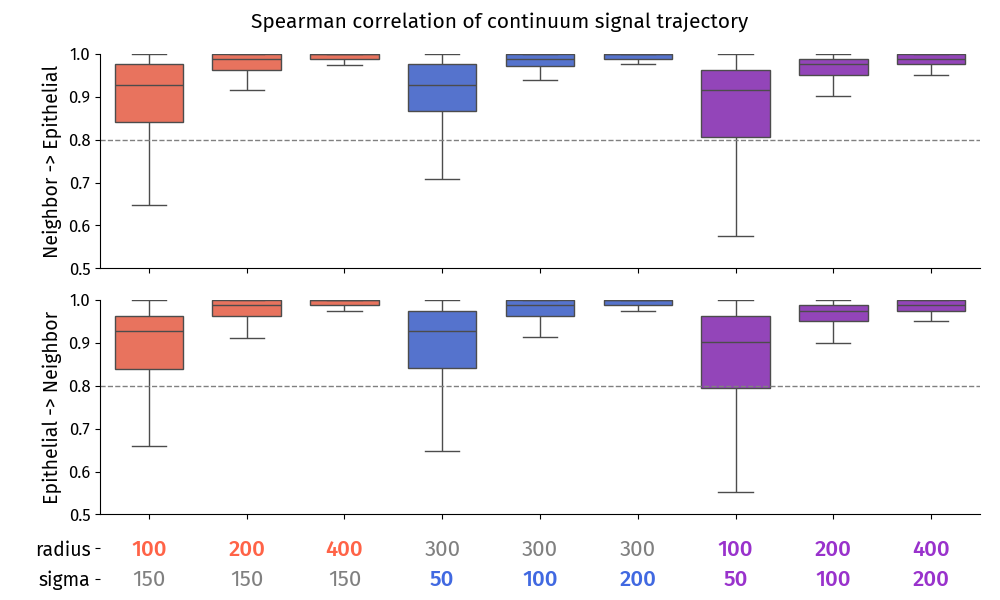

In [20]:
fig, (ax1, ax2, ax3, ax4) = plt.subplots(4,1, figsize=(10, 6), height_ratios=(32,1,32,10))
fig.subplots_adjust(left=0.1, right=0.98, top=0.91, bottom=0.01, hspace=0.1)

for drct, ax, txt in zip(["n2i", "i2n"],[ax1, ax3], ["Neighbor -> Epithelial", "Epithelial -> Neighbor"]):
    sns.boxplot(
        data=plot_df[drct],
        x="comparison",
        y="spearman_rho",
        hue="comparison",
        order=test_name,
        palette=bar_c,
        showfliers=False,
        width=.7,
        ax=ax
    )
    
    ax.axhline(0.8, linestyle="--", linewidth=1, c="grey")
    ax.set_xlabel("")
    ax.set_ylabel(txt, fontsize=14)
    ax.set_ylim(0.5,1)
    ax.set_xticks([n for n in range(9)],labels=[])
    ax.spines[["top","right"]].set_visible(False)
    ax.tick_params("y", labelsize=12)

fig.suptitle("Spearman correlation of continuum signal trajectory", fontsize=15)
ax2.axis("off")

ax4.set_ylim(0,2.4)
ax4.set_xlim(0.5,9.5)
ax4.set_yticks([0.55, 1.65], ["sigma", "radius"], fontsize=14)
ax4.set_xticks([])
ax4.spines[:].set_visible(False)

for n, (r, s) in enumerate(zip(rad_tx, sig_tx)):
    if n//3 == 0:
        ax4.text(s=r, x=n+1, y=1.6, fontsize=16, ha="center", va="center", c=rad_c, fontweight=500)
        ax4.text(s=s, x=n+1,y=0.5, fontsize=16, ha="center", va="center", c="grey")
    elif n//3 == 1:
        ax4.text(s=r, x=n+1, y=1.6, fontsize=16, ha="center", va="center", c="grey")
        ax4.text(s=s, x=n+1,y=0.5, fontsize=16, ha="center", va="center", c=sig_c, fontweight=500)
    else:
        ax4.text(s=r, x=n+1, y=1.6, fontsize=16, ha="center", va="center", c=mix_c, fontweight=500)
        ax4.text(s=s, x=n+1,y=0.5, fontsize=16, ha="center", va="center", c=mix_c, fontweight=500)

fig.savefig(f"{REV_PATH}ori_all_violin.png", dpi=500, format="png", bbox_inches=None)

In [21]:
m_list = ["o", "^", "s"]*3 + ["x"]
l_list = [rad_c]*3 + [sig_c]*3 + [mix_c]*3 +["black"]
rad_tx = [100, 200, 400, 300, 300, 300, 100, 200, 400, 300]
sig_tx = [150, 150, 150, 50, 100, 200, 50, 100, 200, 150]

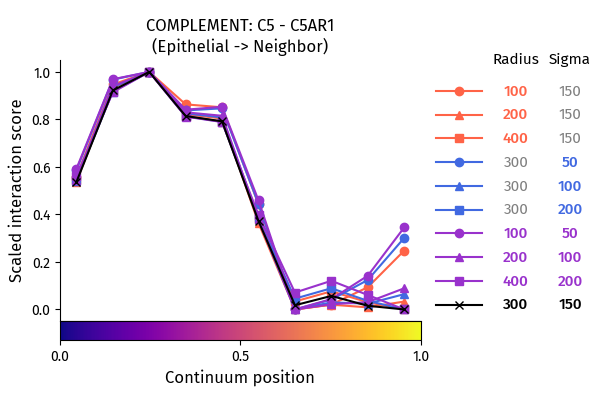

In [22]:
target = "COMPLEMENT: C5 - C5AR1"
d = "Epithelial -> Neighbor"
fig, axes = plt.subplots(2,2,figsize=(6,4),height_ratios=(14,1), width_ratios=(7,3))
axes = axes.flatten()
fig.subplots_adjust(left=0.1, right=0.98, bottom=0.15, top=0.85, hspace=0, wspace=0.05)

for key, m,l in zip(test_name, m_list, l_list):
    axes[0].plot(test_df_s[key]["i2n"][target], label=key, marker=m, c=l)

axes[0].plot(ctrl_df_s["i2n"][target], label="ref", marker="x", c="black")

axes[0].set_title(f"{target}\n({d})")
axes[0].set_ylabel("Scaled interaction score", fontsize=12)

axes[0].spines[["top", "right"]].set_visible(False)
axes[0].set_xticks([])

# legend ax
axes[1].set_ylim(0.5,11.5)
axes[1].set_xlim(0,6)
axes[1].axis("off")
axes[1].text(s="Radius", x=3.2, y=11.5, ha="center", va="center", fontsize=11)
axes[1].text(s="Sigma", x=5.3, y=11.5, ha="center", va="center", fontsize=11)
for n, (r, s, m, l) in enumerate(zip(rad_tx, sig_tx, m_list, l_list)):
    if n == 9:
        axes[1].text(s=r, x=3.2, y=10-n, ha="center", fontsize=11, c="black", fontweight=500)
        axes[1].text(s=s, x=5.3, y=10-n, ha="center", fontsize=11, c="black", fontweight=500)

    elif n//3 == 0:
        axes[1].text(s=r, x=3.2, y=10-n, ha="center", fontsize=11, c="tomato", fontweight=500)
        axes[1].text(s=s, x=5.3, y=10-n, ha="center", fontsize=11, c="grey")
    elif n//3 == 1:
        axes[1].text(s=r, x=3.2, y=10-n, ha="center", fontsize=11, c="grey")
        axes[1].text(s=s, x=5.3, y=10-n, ha="center", fontsize=11, c="royalblue", fontweight=500)
    else:
        axes[1].text(s=r, x=3.2, y=10-n, ha="center", fontsize=11, c="darkorchid", fontweight=500)
        axes[1].text(s=s, x=5.3, y=10-n, ha="center", fontsize=11, c="darkorchid", fontweight=500)
    axes[1].plot([0.1,1,1.9], [10-n+0.2]*3, marker=m, c=l, markevery=[1])

# Continuum position colorbar
norm_cp = matplotlib.colors.Normalize(vmin=0, vmax=1)
sm_cp = plt.cm.ScalarMappable(cmap="plasma", norm=norm_cp)
cp_bar = fig.colorbar(sm_cp, cax=axes[2], ticks=[0, 0.5, 1], orientation="horizontal")
axes[2].set_xlabel("Continuum position", fontsize=12)

axes[3].axis("off")
fig.savefig(f"{REV_PATH}C5_C5AR1.png", dpi=500, format="png", bbox_inches=None)

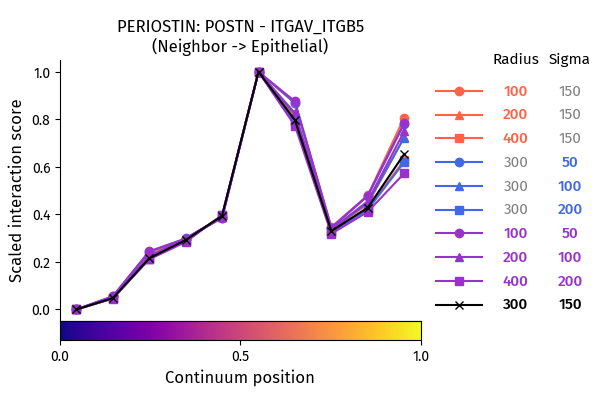

In [23]:
target = "PERIOSTIN: POSTN - ITGAV_ITGB5"
d = "Neighbor -> Epithelial"
fig, axes = plt.subplots(2,2,figsize=(6,4),height_ratios=(14,1), width_ratios=(7,3))
axes = axes.flatten()
fig.subplots_adjust(left=0.1, right=0.98, bottom=0.15, top=0.85, hspace=0, wspace=0.05)

for key, m,l in zip(test_name, m_list, l_list):
    axes[0].plot(test_df_s[key]["n2i"][target], label=key, marker=m, c=l)

axes[0].plot(ctrl_df_s["n2i"][target], label="ref", marker="x", c="black")
axes[0].set_title(f"{target}\n({d})")
axes[0].set_ylabel("Scaled interaction score", fontsize=12)

axes[0].spines[["top", "right"]].set_visible(False)
axes[0].set_xticks([])

# legend ax
axes[1].set_ylim(0.5,11.5)
axes[1].set_xlim(0,6)
axes[1].axis("off")
axes[1].text(s="Radius", x=3.2, y=11.5, ha="center", va="center", fontsize=11)
axes[1].text(s="Sigma", x=5.3, y=11.5, ha="center", va="center", fontsize=11)
for n, (r, s, m, l) in enumerate(zip(rad_tx, sig_tx, m_list, l_list)):
    if n == 9:
        axes[1].text(s=r, x=3.2, y=10-n, ha="center", fontsize=11, c="black", fontweight=500)
        axes[1].text(s=s, x=5.3, y=10-n, ha="center", fontsize=11, c="black", fontweight=500)

    elif n//3 == 0:
        axes[1].text(s=r, x=3.2, y=10-n, ha="center", fontsize=11, c="tomato", fontweight=500)
        axes[1].text(s=s, x=5.3, y=10-n, ha="center", fontsize=11, c="grey")
    elif n//3 == 1:
        axes[1].text(s=r, x=3.2, y=10-n, ha="center", fontsize=11, c="grey")
        axes[1].text(s=s, x=5.3, y=10-n, ha="center", fontsize=11, c="royalblue", fontweight=500)
    else:
        axes[1].text(s=r, x=3.2, y=10-n, ha="center", fontsize=11, c="darkorchid", fontweight=500)
        axes[1].text(s=s, x=5.3, y=10-n, ha="center", fontsize=11, c="darkorchid", fontweight=500)
    axes[1].plot([0.1,1,1.9], [10-n+0.2]*3, marker=m, c=l, markevery=[1])


# Continuum position colorbar
norm_cp = matplotlib.colors.Normalize(vmin=0, vmax=1)
sm_cp = plt.cm.ScalarMappable(cmap="plasma", norm=norm_cp)
cp_bar = fig.colorbar(sm_cp, cax=axes[2], ticks=[0, 0.5, 1], orientation="horizontal")
axes[2].set_xlabel("Continuum position", fontsize=12)

axes[3].axis("off")
fig.savefig(f"{REV_PATH}POSTN_ITGAV_ITGB5.png", dpi=500, format="png", bbox_inches=None)

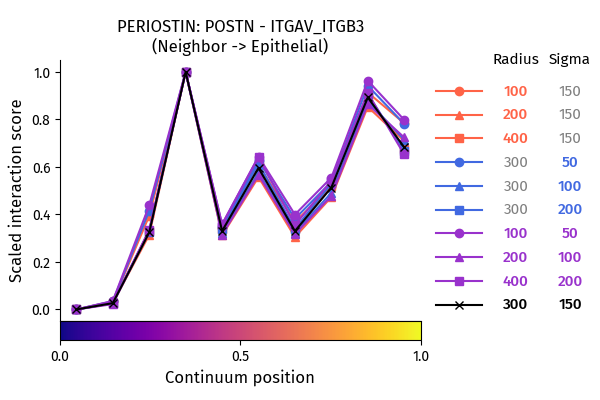

In [24]:
target = "PERIOSTIN: POSTN - ITGAV_ITGB3"

d = "Neighbor -> Epithelial"
fig, axes = plt.subplots(2,2,figsize=(6,4),height_ratios=(14,1), width_ratios=(7,3))
axes = axes.flatten()
fig.subplots_adjust(left=0.1, right=0.98, bottom=0.15, top=0.85, hspace=0, wspace=0.05)

for key, m,l in zip(test_name, m_list, l_list):
    axes[0].plot(test_df_s[key]["n2i"][target], label=key, marker=m, c=l)

axes[0].plot(ctrl_df_s["n2i"][target], label="ref", marker="x", c="black")
axes[0].set_title(f"{target}\n({d})")
axes[0].set_ylabel("Scaled interaction score", fontsize=12)

axes[0].spines[["top", "right"]].set_visible(False)
axes[0].set_xticks([])

# legend ax
axes[1].set_ylim(0.5,11.5)
axes[1].set_xlim(0,6)
axes[1].axis("off")
axes[1].text(s="Radius", x=3.2, y=11.5, ha="center", va="center", fontsize=11)
axes[1].text(s="Sigma", x=5.3, y=11.5, ha="center", va="center", fontsize=11)
for n, (r, s, m, l) in enumerate(zip(rad_tx, sig_tx, m_list, l_list)):
    if n == 9:
        axes[1].text(s=r, x=3.2, y=10-n, ha="center", fontsize=11, c="black", fontweight=500)
        axes[1].text(s=s, x=5.3, y=10-n, ha="center", fontsize=11, c="black", fontweight=500)

    elif n//3 == 0:
        axes[1].text(s=r, x=3.2, y=10-n, ha="center", fontsize=11, c="tomato", fontweight=500)
        axes[1].text(s=s, x=5.3, y=10-n, ha="center", fontsize=11, c="grey")
    elif n//3 == 1:
        axes[1].text(s=r, x=3.2, y=10-n, ha="center", fontsize=11, c="grey")
        axes[1].text(s=s, x=5.3, y=10-n, ha="center", fontsize=11, c="royalblue", fontweight=500)
    else:
        axes[1].text(s=r, x=3.2, y=10-n, ha="center", fontsize=11, c="darkorchid", fontweight=500)
        axes[1].text(s=s, x=5.3, y=10-n, ha="center", fontsize=11, c="darkorchid", fontweight=500)
    axes[1].plot([0.1,1,1.9], [10-n+0.2]*3, marker=m, c=l, markevery=[1])


# Continuum position colorbar
norm_cp = matplotlib.colors.Normalize(vmin=0, vmax=1)
sm_cp = plt.cm.ScalarMappable(cmap="plasma", norm=norm_cp)
cp_bar = fig.colorbar(sm_cp, cax=axes[2], ticks=[0, 0.5, 1], orientation="horizontal")
axes[2].set_xlabel("Continuum position", fontsize=12)

axes[3].axis("off")

fig.savefig(f"{REV_PATH}POSTN_ITGAV_ITGB3.png", dpi=500, format="png", bbox_inches=None)